### Hoe deze notebook uit te voeren

Je kunt deze notebook lokaal uitvoeren op je computer via één van de twee opties hieronder.  
Beide opties vereisen dat je de open-source solver **MIP** installeert (zie onderaan).

---

### Python Installatie:

#### Optie 1 — Installeer Anaconda (aanbevolen voor beginners)

Met Anaconda krijg je in één keer Python, Jupyter Notebook en alle veelgebruikte wetenschappelijke pakketten.

1. Download Anaconda voor jouw besturingssysteem:  
   https://www.anaconda.com/products/distribution

2. Installeer Anaconda via de installer.

3. Open **Anaconda Navigator** → **Jupyter Notebook**.

4. Navigeer naar de map waar deze notebook staat en open het bestand.

Volledige installatiehandleiding:  
https://docs.anaconda.com/anaconda/install/

---

#### Optie 2 — Gebruik Python zonder Anaconda (native installatie)

Als je liever een lichtere installatie hebt, kun je Python zelf installeren en Jupyter toevoegen via `pip`.

1. Download en installeer Python (versie 3.10 of hoger aangeraden):  
   https://www.python.org/downloads/

2. Installeer Jupyter via de terminal of command prompt:

    ```
    pip install jupyter
    ```

### Jupyter Notebook starten:

Je kunt Jupyter op twee manieren starten:

**Via Anaconda Navigator:**
- Open *Anaconda Navigator*
- Klik op **Launch** bij *Jupyter Notebook*

**Via de terminal / command prompt:**
```   
jupyter notebook 
```


### Installatie van de open-source solver MIP en pakketten:

Deze notebook gebruikt de Mixed Integer Programming solver **MIP** en pakketten pandas en matplotlib.

Met onderstaande code worden deze geïnstalleerd (als dat nog niet het geval zou zijn).

In [1]:
%pip install mip
%pip install pandas
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


##### Nu zijn we klaar om de rest van deze notebook uit te voeren: model opbouwen, model oplossen, oplossing uitlezen, oplossing visualiseren.

In [2]:
from mip import * #Model, xsum, BINARY, INTEGER, CONTINUOUS, MINIMIZE
import pandas as pd
import math
import matplotlib.pyplot as plt; plt.rcdefaults()
import time

pd.set_option('display.max_rows',200) #number of rows to be displayed when a df is printedb

#### Probleemformulering

##### Variabelen

$g_i$ → Gietstarttijd van lading i  
$pg_i$ → Gietprocestijd van lading i  
$s_i$ → Smeltstarttijd van lading i  

##### Parameters

$ps$ → Smeltprocestijd  
$t$ → Maximale productietijd voor een lading


$$
\begin{aligned}
\min \quad  g_{I-1} & + pg_{I-1} \quad  && (1) \\
s_{i} + ps &\le s_{i+1} && \forall i \in (0,I-1) \quad &(2) \\
g_{i} + pg_i &= g_{i+1} && \forall i \in (0,I-1) \quad &(3) \\
 s_{i} + ps &\le g_{i} && \forall i \in (0,I) \quad &(4) \\
g_{i} - s_i - ps &\le t && \forall i \in (0,I) \quad &(5) \\
g_i \in \mathbb{R}_+; & \quad s_i \in \mathbb{R}_+ \\
1 \le pg& \le 2 \\
ps &= 3 \\
tg &= 5
\end{aligned}
$$


(1) → Minimalisatie van gietstarttijden en gietprocestijden.  
(2) → Het smelten van de volgende lading mag pas beginnen nadat het smelten van de vorige lading is voltooid.  
(3) → Het gieten van de volgende lading moet pas beginnen nadat het gieten van de vorige lading is voltooid.  
(4) → Het gieten van een lading moet pas beginnen nadat het smelten van die lading is voltooid.  
(5) → Het smelten en gieten van een lading mag niet langer duren dan de maximale productietijd.  

In [3]:
# Declaratie van variabelen en parameters.

i = range(0, 5)
I = len(i)

model = Model("Schedule melting-casting")

g  = [model.add_var(lb=0, var_type=CONTINUOUS, name=f"start_gieten[{k}]")   for k in i]
s  = [model.add_var(lb=0, var_type=CONTINUOUS, name=f"start_smelten[{k}]") for k in i]
pg = [model.add_var(lb=1, ub=2, var_type=CONTINUOUS, name=f"processtimegieten[{k}]") for k in i]

ps = 3
t = 5

In [4]:
# Definitie van doelfunctie

model.objective = g[I-1] + pg[I-1] # (1)
model.sense = MINIMIZE

In [5]:
# Definitie van beperkingen

# s[i] + ps <= s[i+1] # (2)
for i in range(I-1):
    model += s[i] + ps <= s[i+1]

# g[i] + pg[i] == g[i+1] # (3)
for i in range(I-1):
    model += g[i] + pg[i] == g[i+1]

# g[i] >= s[i] + ps # (4)
for i in range(I):
    model += g[i] >= s[i] + ps

# g[i] + s[i] <= t # (5)
for i in range(I):
    model += g[i] - s[i] - ps <= t


In [6]:
model.optimize()

Welcome to the CBC MILP Solver 
Version: Trunk
Build Date: Oct 24 2021 

Starting solution of the Linear programming problem using Dual Simplex



<OptimizationStatus.OPTIMAL: 0>

In [7]:
# Oplossingen ophalen

st_smelten  = [s[i].x for i in range(I)]
end_smelten = [s[i].x + ps for i in range(I)]

st_gieten   = [g[i].x for i in range(I)]
end_gieten  = [g[i].x + pg[i].x for i in range(I)]

loopduur = [st_gieten[i] - end_smelten[i] for i in range(I)]

result = pd.DataFrame({"Start Smelten":st_smelten,"Einde Smelten":end_smelten,"Start Gieten":st_gieten,"Einde Gieten":end_gieten,"Loopduur":loopduur})

In [8]:
result

,Start Smelten,Einde Smelten,Start Gieten,Einde Gieten,Loopduur
0,0.0,3.0,8.0,9.0,5.0
1,3.0,6.0,9.0,11.0,3.0
2,6.0,9.0,11.0,13.0,2.0
3,9.0,12.0,13.0,15.0,1.0
4,12.0,15.0,15.0,16.0,0.0


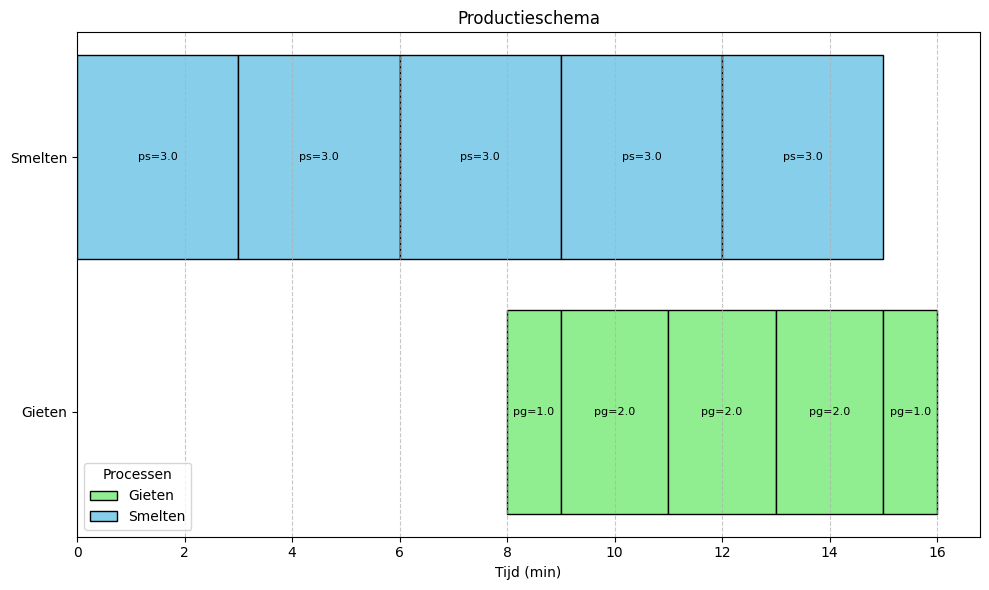

In [9]:
#Gantt chart
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Gieten
for _, row in result.iterrows():
    width = row['Einde Gieten'] - row['Start Gieten']  # Calculate width (duration)
    ax.barh(y=0, width=width, left=row['Start Gieten'], color='lightgreen', edgecolor='black', label='Gieten')
    # Add text annotation for the width
    ax.text(row['Start Gieten'] + width / 2, 0, f'pg={width}', 
            va='center', ha='center', color='black', fontsize=8)

# Plot Smelten
for _, row in result.iterrows():
    width = row['Einde Smelten'] - row['Start Smelten']  # Calculate width (duration)
    ax.barh(y=1, width=width, left=row['Start Smelten'], color='skyblue', edgecolor='black', label='Smelten')
    # Add text annotation for the width
    ax.text(row['Start Smelten'] + width / 2, 1, f'ps={width}', 
            va='center', ha='center', color='black', fontsize=8)

# Format
ax.set_yticks([0, 1])
ax.set_yticklabels(['Gieten', 'Smelten'])
ax.set_xlabel('Tijd (min)')
ax.set_title('Productieschema')
ax.grid(axis='x', linestyle='--', alpha=0.7)

handles, labels = ax.get_legend_handles_labels()
unique_labels = dict(zip(labels, handles))
ax.legend(unique_labels.values(), unique_labels.keys(), title="Processen")

# Display chart
plt.tight_layout()
plt.show()